In [1]:
!pip install ultralytics


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 10.1 MB/s eta 0:00:00


In [2]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

In [3]:
import zipfile
zipfile.ZipFile("/content/seatbelt.v1i.yolov11.zip").extractall()

In [4]:
model.train(data='/content/seatbelt.v1i.yolov11/data.yaml',epochs=20)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/seatbelt.v1i.yolov11/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=Fals

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a906e193890>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [5]:
metrics = model.val(
    data="/content/seatbelt.v1i.yolov11/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True
)

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1298.4±382.9 MB/s, size: 65.9 KB)
val: Scanning /content/seatbelt.v1i.yolov11/test/labels... 86 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 86/86 1.2Kit/s 0.1s
val: New cache created: /content/seatbelt.v1i.yolov11/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.0it/s 3.1s
                   all         86        110      0.747      0.537      0.647      0.283
Speed: 5.7ms preprocess, 6.2ms inference, 0.0ms loss, 4.6ms postprocess per image
Results saved to /content/runs/detect/val
mAP50: 0.6470693688116445
mAP50-95: 0.2833435800897736
Precision: 0.7469723816964471
Recall: 0.5367570237825208


In [6]:
from ultralytics import YOLO
from pathlib import Path

model = YOLO("/content/runs/detect/train/weights/best.pt")

test_dir = Path("/content/seatbelt.v1i.yolov11/test/images")

results = model.predict(
    source=str(test_dir),
    imgsz=640,
    conf=0.25,
    save=True
)

print("Predictions complete!")
print("Saved folder:", results[0].save_dir)


image 1/86 /content/seatbelt.v1i.yolov11/test/images/2QEZBAIR5LMV_jpg.rf.a4484e6e571c568d64554582af3c8501.jpg: 640x640 (no detections), 21.7ms
image 2/86 /content/seatbelt.v1i.yolov11/test/images/3294ALSUWA6Z_jpg.rf.c0911d4c8abea2039f2027b023b09d76.jpg: 640x640 2 Seat-Belt Detection - v5 2023-10-12 10-52pms, 17.0ms
image 3/86 /content/seatbelt.v1i.yolov11/test/images/995XXQZ3GW1W_jpg.rf.117e986b3c2e771261771f459c9f7562.jpg: 640x640 1 Seat-Belt Detection - v5 2023-10-12 10-52pm, 25.9ms
image 4/86 /content/seatbelt.v1i.yolov11/test/images/AXHTBH9XH5H8_jpg.rf.5a14b3908a1cc20075942d26053d03d9.jpg: 640x640 1 Seat-Belt Detection - v5 2023-10-12 10-52pm, 34.4ms
image 5/86 /content/seatbelt.v1i.yolov11/test/images/BHQ3NKJX6AEN_jpg.rf.c36f2e871842f1520bf549f808de9711.jpg: 640x640 1 Seat-Belt Detection - v5 2023-10-12 10-52pm, 29.7ms
image 6/86 /content/seatbelt.v1i.yolov11/test/images/D1PACYZNVTAG_jpg.rf.db67c000a109cfd91178868d9efafe8c.jpg: 640x640 (no detections), 44.4ms
image 7/86 /content/

Total prediction images: 86
TJWLWJTMGQDS_jpg.rf.9ca1ba518d60944ef5947611fec837ff.jpg


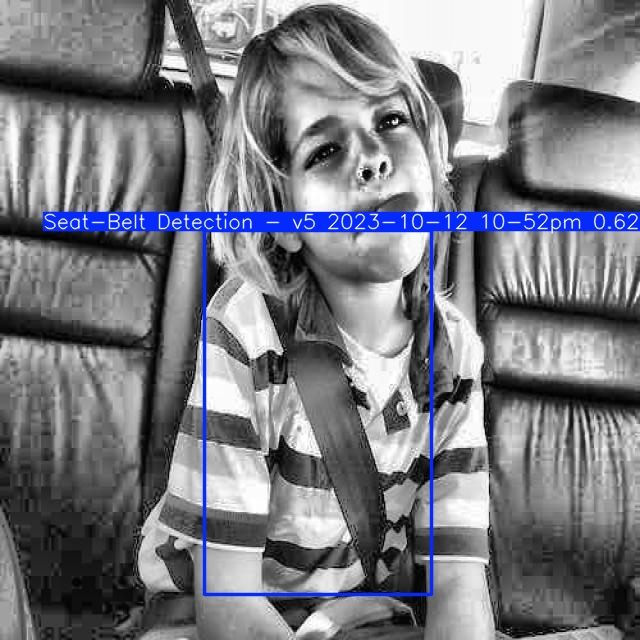

ka_154_jpg.rf.357536a3c29449332076e55cdc23bbc2.jpg


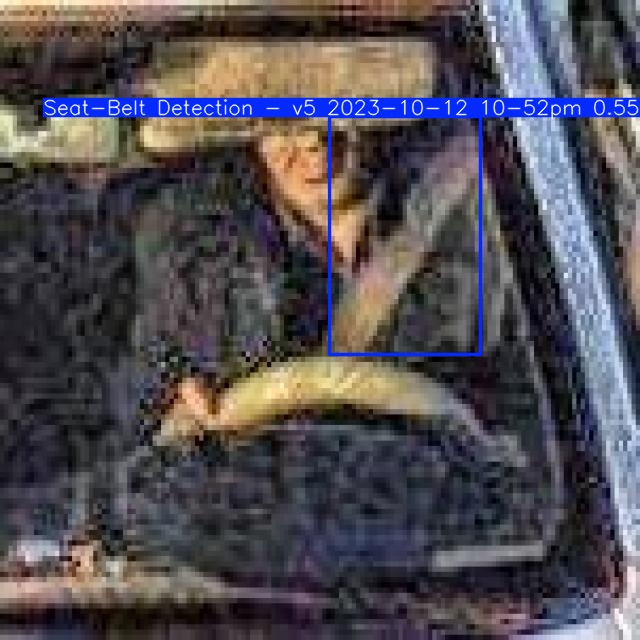

gettyimages-93354869-612x612_jpg.rf.18b0890aa32cc851641f6ae13031e43d.jpg


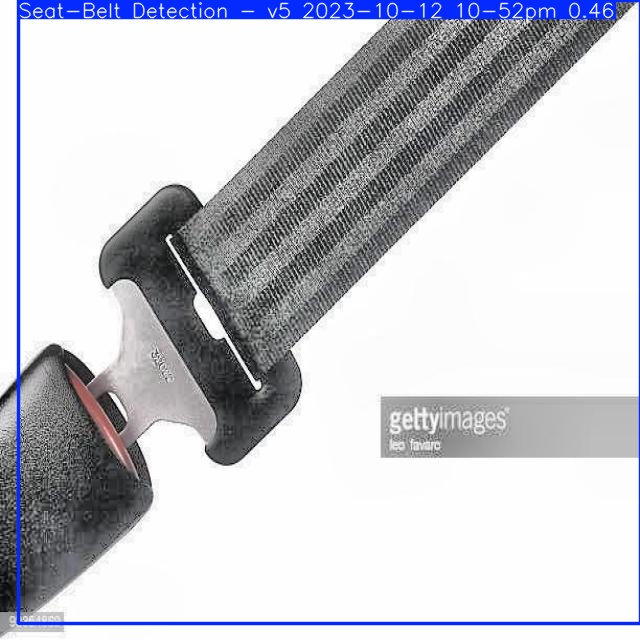

close-up-seat-belt-in-modern-car-photo_jpg.rf.bfdf07e5f89dcb60a3b9e25128cba168.jpg


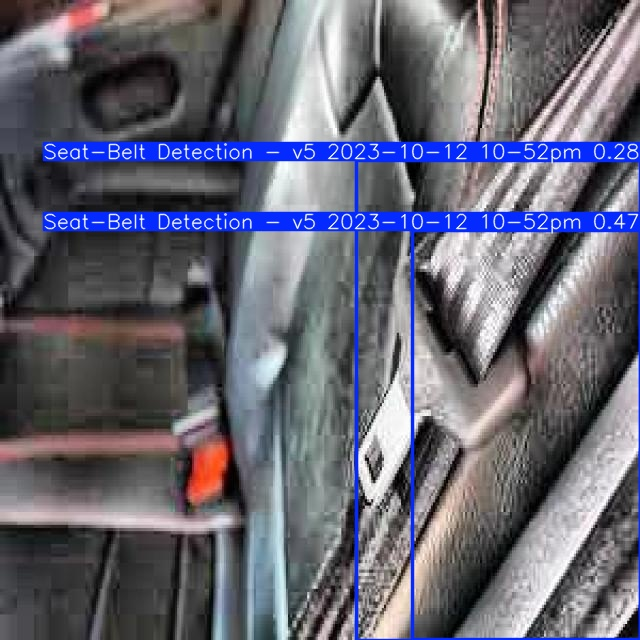

S36XK32QTJZT_jpg.rf.baaf798017dfb836ab00e25696b25634.jpg


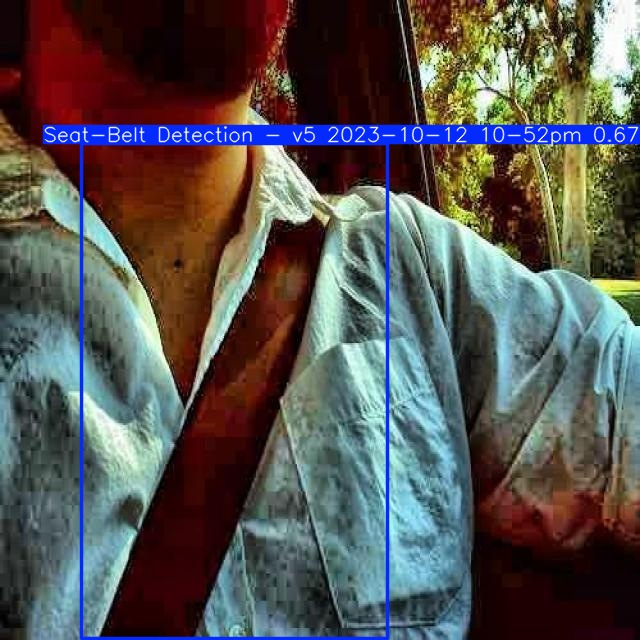

In [7]:
from IPython.display import display, Image
from pathlib import Path

output_dir = Path("/content/runs/detect/predict")

images = list(output_dir.glob("*.jpg")) + list(output_dir.glob("*.png"))

print("Total prediction images:", len(images))

for img in images[:5]:
    print(img.name)
    display(Image(filename=str(img)))

In [8]:
from google.colab import files

# Apni file ka sahi path yahan dein (misal ke tor par YOLOv11 ka weights path)
files.download('/content/runs/detect/train/weights/best.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>